1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step


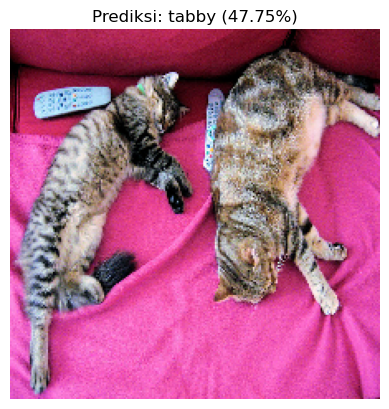

In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions
from tensorflow.keras.utils import load_img, img_to_array

model = tf.keras.applications.MobileNetV2(weights='imagenet')

# Preprocessing gambar baru
img_path = 'cat.jpg'
img = load_img(img_path, target_size=(224, 224))
x = img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# Prediksi
preds = model.predict(x)
top_pred = decode_predictions(preds, top=1)[0][0]  # Ambil prediksi teratas

# Tampilkan gambar dan hasil prediksi
plt.imshow(np.array(img).astype('uint8'))
plt.title(f'Prediksi: {top_pred[1]} ({top_pred[2]*100:.2f}%)')
plt.axis('off')
plt.show()

Found 2 files.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


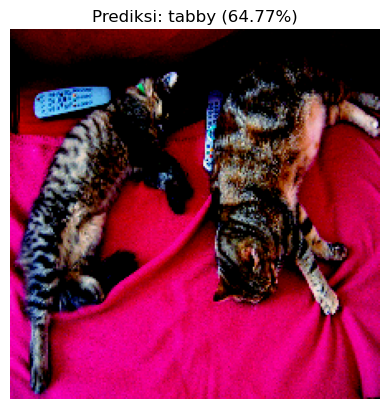

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.99978113].


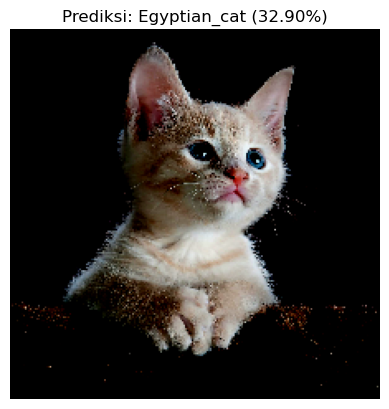

2025-06-25 12:39:55.733043: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [16]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions

# Load dataset dari folder
dataset = tf.keras.utils.image_dataset_from_directory(
    'data/test',        
    labels=None,          
    image_size=(224, 224),
    batch_size=1,         
    shuffle=False
)

model = tf.keras.applications.MobileNetV2(weights='imagenet')

for batch in dataset:
    img = batch.numpy()  
    img_preproc = preprocess_input(img) 
    preds = model.predict(img_preproc)
    top_pred = decode_predictions(preds, top=1)[0][0]

    plt.imshow(img[0])  
    plt.title(f"Prediksi: {top_pred[1]} ({top_pred[2]*100:.2f}%)")
    plt.axis('off')
    plt.show()


Found 3 files.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.99978113].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9966395].


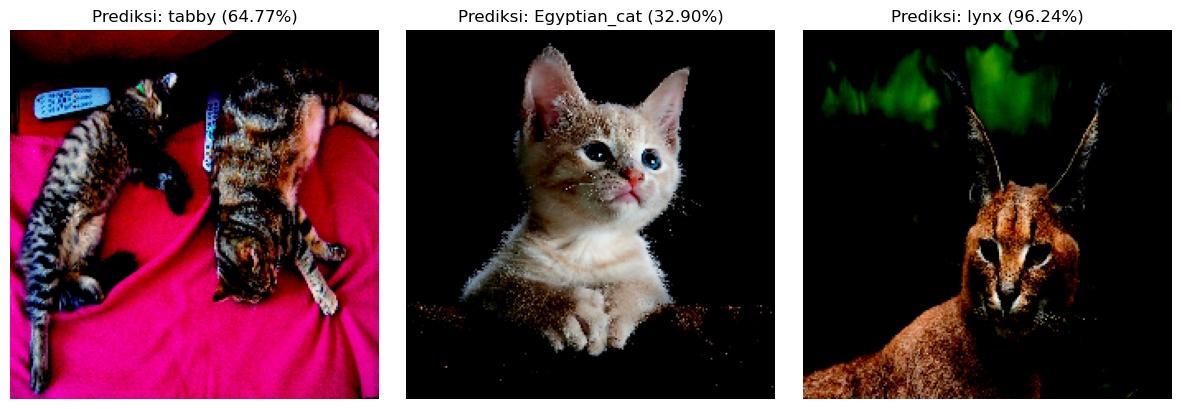

In [18]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions

dataset = tf.keras.utils.image_dataset_from_directory(
    'data/test',        
    labels=None,          
    image_size=(224, 224),
    batch_size=1,         
    shuffle=False
)

model = tf.keras.applications.MobileNetV2(weights='imagenet')

# Simpan hasil gambar dan prediksi ke list
images = []
titles = []

for batch in dataset:
    img = batch.numpy()
    img_preproc = preprocess_input(img) 
    preds = model.predict(img_preproc)
    top_pred = decode_predictions(preds, top=1)[0][0]

    images.append(img[0])
    titles.append(f"Prediksi: {top_pred[1]} ({top_pred[2]*100:.2f}%)") 

# Tampilkan semua dalam 1 plot grid
num_images = len(images)
cols = 4
rows = int(np.ceil(num_images / cols))

plt.figure(figsize=(4*cols, 4*rows))
for i in range(num_images):
    plt.subplot(rows, cols, i+1)
    if images[i].dtype == np.uint8 or images[i].max() > 1.5:
        plt.imshow(images[i].astype('uint8'))
    else:
        plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()
